<a href="https://colab.research.google.com/github/EmmanuelPhelps/cyberbullying-detection-nlp/blob/main/Cyberbullying_Transformer_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## 4.7 Google Colab GPU Environment Setup

Google Colab is used as a GPU-enabled computing environment for fine-tuning BERT and RoBERTa.

The original training, validation, and testing partitions are retained to ensure consistency with the Logistic Regression baseline.

Transformer models and evaluation results will be saved to Google Drive and subsequently transferred to the original VS Code project.

The computing environment is verified before model training begins.


In [ ]:

import torch  # Import the PyTorch deep learning framework
import platform  # Inspect the Python environment

print("Python version:", platform.python_version())  # Display Python version
print("PyTorch version:", torch.__version__)  # Display installed PyTorch version
print("CUDA available:", torch.cuda.is_available())  # Check GPU availability

if torch.cuda.is_available():  # Check whether a CUDA GPU is active
    print("GPU:", torch.cuda.get_device_name(0))  # Display GPU model
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))  # Display GPU memory
else:  # Handle unavailable GPU
    print("No GPU detected. Check Colab runtime settings.")  # Display configuration warning


Python version: 3.13.16
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56



### 4.8 Google Drive Integration and Project Storage

Google Drive is connected to the GPU-enabled Colab environment to provide persistent storage for transformer training.

A dedicated project directory is created to store the existing dataset partitions, label mappings, trained BERT and RoBERTa models, checkpoints, and evaluation results.

This ensures that transformer outputs can be transferred back to the original VS Code project without modifying the established Logistic Regression baseline.


In [ ]:

from google.colab import drive  # Access Google Drive from Colab
from pathlib import Path  # Manage project directories

drive.mount("/content/drive")  # Connect Google Drive to Colab

project_dir = Path("/content/drive/MyDrive/Cyberbullying_NLP_Final_2026")  # Define persistent project directory
results_dir = project_dir / "results"  # Define results storage directory

for folder in ["datasets", "bert", "roberta", "comparisons", "figures"]:  # Define required project folders
    (results_dir / folder).mkdir(parents=True, exist_ok=True)  # Create missing directories

print("Google Drive project:", project_dir)  # Display project location
print("Results directory:", results_dir)  # Display results location
print("Project folder exists:", project_dir.exists())  # Confirm successful directory creation


Mounted at /content/drive
Google Drive project: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026
Results directory: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results
Project folder exists: True



### 4.9 Dataset Transfer and Integrity Verification

The existing transformer training, validation, and held-out testing datasets are transferred from the local VS Code project to Google Drive.

The original dataset partitions and six-class label mapping are retained to ensure consistency with the Logistic Regression baseline.

Dataset dimensions, label distributions, and text overlap are checked before GPU-based model training.


In [ ]:

import pandas as pd  # Load datasets
import json  # Read class mapping
from pathlib import Path  # Manage dataset paths

dataset_dir = Path("/content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/datasets")  # Define Google Drive dataset location

train_df = pd.read_csv(dataset_dir / "transformer_train.csv")  # Load training dataset
val_df = pd.read_csv(dataset_dir / "transformer_validation.csv")  # Load validation dataset
test_df = pd.read_csv(dataset_dir / "test_data.csv")  # Load testing dataset

with open(dataset_dir / "label_mapping.json", "r", encoding="utf-8") as file:  # Open class mapping
    label2id = json.load(file)  # Read class identifiers

print("Training records:", len(train_df))  # Display training size
print("Validation records:", len(val_df))  # Display validation size
print("Testing records:", len(test_df))  # Display testing size
print("Training columns:", train_df.columns.tolist())  # Check training columns
print("Testing columns:", test_df.columns.tolist())  # Check testing columns
print("Number of classes:", len(label2id))  # Confirm class count

print("Train-validation overlap:", len(set(train_df["text"]) & set(val_df["text"])))  # Check training-validation overlap
print("Train-test overlap:", len(set(train_df["text"]) & set(test_df["text"])))  # Check training-testing overlap
print("Validation-test overlap:", len(set(val_df["text"]) & set(test_df["text"])))  # Check validation-testing overlap


Training records: 31596
Validation records: 3511
Testing records: 8777
Training columns: ['text', 'label']
Testing columns: ['text', 'label']
Number of classes: 6
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0



### 4.10 BERT GPU Dataset Preparation

The verified training, validation, and held-out testing partitions are prepared for BERT fine-tuning in Google Colab.

The six cyberbullying categories are encoded using the original label mapping established during preprocessing.

The pretrained bert-base-uncased tokenizer converts tweets into input identifiers and attention masks, with a maximum sequence length of 128 tokens.

Dynamic padding is configured to reduce unnecessary memory usage during GPU training.

The original testing partition remains excluded from model training and validation to preserve the integrity of the final comparison.


In [ ]:

import torch  # Access PyTorch GPU functionality
from datasets import Dataset  # Create Hugging Face datasets
from transformers import AutoTokenizer, DataCollatorWithPadding  # Load tokenizer and padding tools

assert torch.cuda.is_available(), "Enable a GPU runtime before continuing."  # Require GPU acceleration

class_names = sorted(label2id, key=label2id.get)  # Preserve original class order
id2label = {index: label for label, index in label2id.items()}  # Create reverse label mapping

for frame in [train_df, val_df, test_df]:  # Process each dataset consistently
    frame["labels"] = frame["label"].map(label2id)  # Convert class names into numeric identifiers
    assert frame["labels"].notna().all(), "Unknown class label detected."  # Verify label encoding
    frame["labels"] = frame["labels"].astype(int)  # Store integer class identifiers

bert_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")  # Load pretrained BERT tokenizer

def tokenize_bert(batch):  # Define tokenisation function
    return bert_tokenizer(batch["text"], truncation=True, max_length=128)  # Tokenise tweets

bert_train_dataset = Dataset.from_pandas(train_df[["text", "labels"]], preserve_index=False)  # Create training dataset
bert_val_dataset = Dataset.from_pandas(val_df[["text", "labels"]], preserve_index=False)  # Create validation dataset
bert_test_dataset = Dataset.from_pandas(test_df[["text", "labels"]], preserve_index=False)  # Create held-out testing dataset

bert_train_dataset = bert_train_dataset.map(tokenize_bert, batched=True, remove_columns=["text"])  # Tokenise training records
bert_val_dataset = bert_val_dataset.map(tokenize_bert, batched=True, remove_columns=["text"])  # Tokenise validation records
bert_test_dataset = bert_test_dataset.map(tokenize_bert, batched=True, remove_columns=["text"])  # Tokenise testing records

bert_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer)  # Configure dynamic batch padding

print("GPU:", torch.cuda.get_device_name(0))  # Display available GPU
print("Training samples:", len(bert_train_dataset))  # Confirm training size
print("Validation samples:", len(bert_val_dataset))  # Confirm validation size
print("Testing samples:", len(bert_test_dataset))  # Confirm held-out testing size
print("Classes:", class_names)  # Display class order
print("Dataset features:", bert_train_dataset.column_names)  # Display model input fields


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/31596 [00:00<?, ? examples/s]

Map:   0%|          | 0/3511 [00:00<?, ? examples/s]

Map:   0%|          | 0/8777 [00:00<?, ? examples/s]

GPU: Tesla T4
Training samples: 31596
Validation samples: 3511
Testing samples: 8777
Classes: ['age', 'ethnicity', 'gender', 'not_cyberbullying', 'other_cyberbullying', 'religion']
Dataset features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask']



### 4.11 BERT Fine-Tuning Configuration

The pretrained bert-base-uncased model is configured for six-class cyberbullying classification using GPU acceleration.

Fine-tuning uses a learning rate of 2e-5, a training batch size of 16, and a maximum sequence length of 128 tokens.

The model is trained for up to three epochs, with validation performed after each epoch.

Macro-F1 is used to select the best checkpoint because it gives equal importance to all six cyberbullying categories.

Training checkpoints and model evaluation outputs are saved to Google Drive to support reproducibility and comparison with RoBERTa.


In [ ]:

import numpy as np  # Process model predictions
import torch  # Access GPU acceleration
from sklearn.metrics import accuracy_score, precision_recall_fscore_support  # Calculate classification metrics
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer  # Configure BERT training

bert_output_dir = results_dir / "bert"  # Define persistent BERT output folder
bert_output_dir.mkdir(parents=True, exist_ok=True)  # Create BERT folder if needed

bert_model = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=6, id2label={index: label for label, index in label2id.items()}, label2id=label2id)  # Initialise six-class BERT

def compute_metrics(eval_pred):  # Define validation metrics
    logits, labels = eval_pred  # Extract model predictions and true labels
    predictions = np.argmax(logits, axis=-1)  # Convert logits to predicted classes
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average="macro", zero_division=0)  # Calculate macro metrics
    return {"accuracy": accuracy_score(labels, predictions), "macro_precision": precision, "macro_recall": recall, "macro_f1": f1}  # Return evaluation results

training_args = TrainingArguments(
    output_dir=str(bert_output_dir / "checkpoints"),  # Save model checkpoints
    learning_rate=2e-5,  # Set learning rate
    per_device_train_batch_size=16,  # Set training batch size
    per_device_eval_batch_size=32,  # Set validation batch size
    num_train_epochs=3,  # Train for three epochs
    eval_strategy="epoch",  # Evaluate after each epoch
    save_strategy="epoch",  # Save after each epoch
    load_best_model_at_end=True,  # Restore best validation checkpoint
    metric_for_best_model="macro_f1",  # Select best macro-F1 checkpoint
    greater_is_better=True,  # Maximise macro-F1
    save_total_limit=2,  # Limit stored checkpoints
    fp16=torch.cuda.is_available(),  # Use mixed precision when CUDA is available
    logging_steps=100,  # Record training progress
    report_to="none",  # Disable external experiment trackers
    seed=42,  # Set reproducibility seed
    data_seed=42,  # Set dataset sampling seed
)

bert_trainer = Trainer(
    model=bert_model,  # Provide BERT model
    args=training_args,  # Apply training settings
    train_dataset=bert_train_dataset,  # Supply training dataset
    eval_dataset=bert_val_dataset,  # Supply validation dataset
    data_collator=bert_collator,  # Apply dynamic padding
    compute_metrics=compute_metrics,  # Calculate validation metrics
)

print("GPU:", torch.cuda.get_device_name(0))  # Confirm GPU
print("Training samples:", len(bert_train_dataset))  # Confirm training records
print("Validation samples:", len(bert_val_dataset))  # Confirm validation records
print("Epochs:", training_args.num_train_epochs)  # Display training epochs
print("Batch size:", training_args.per_device_train_batch_size)  # Display training batch size
print("Checkpoint folder:", training_args.output_dir)  # Display checkpoint location


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


GPU: Tesla T4
Training samples: 31596
Validation samples: 3511
Epochs: 3
Batch size: 16
Checkpoint folder: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/bert/checkpoints



### 4.12 BERT Fine-Tuning and Checkpoint Saving

The pretrained BERT model is fine-tuned on the 31,596 training tweets for up to three epochs using GPU acceleration.

After each epoch, performance is measured on the 3,511 validation records using accuracy, macro-precision, macro-recall, and macro-F1.

The checkpoint achieving the highest validation macro-F1 is selected as the final BERT model.

Model weights, tokenizer files, training metrics, and validation results are saved to Google Drive for reproducibility and subsequent comparison with the Logistic Regression baseline and RoBERTa.

The held-out test dataset is excluded from training and checkpoint selection.


In [ ]:

import json  # Save training metrics and metadata

bert_train_result = bert_trainer.train()  # Fine-tune BERT and select the best validation checkpoint

bert_final_dir = bert_output_dir / "best_model"  # Define final model storage location
bert_trainer.save_model(str(bert_final_dir))  # Save best BERT model
bert_tokenizer.save_pretrained(str(bert_final_dir))  # Save matching tokenizer

bert_validation_metrics = bert_trainer.evaluate()  # Evaluate selected model on validation data

with open(bert_output_dir / "training_metrics.json", "w", encoding="utf-8") as file:  # Create training metrics file
    json.dump(bert_train_result.metrics, file, indent=4)  # Save training metrics

with open(bert_output_dir / "validation_metrics.json", "w", encoding="utf-8") as file:  # Create validation metrics file
    json.dump(bert_validation_metrics, file, indent=4)  # Save validation metrics

print("Training completed.")  # Confirm training completion
print("Best checkpoint:", bert_trainer.state.best_model_checkpoint)  # Display selected checkpoint
print("Validation macro-F1:", round(bert_validation_metrics["eval_macro_f1"], 4))  # Display validation macro-F1
print("Saved model:", bert_final_dir)  # Display model location


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,0.308545,0.288783,0.890914,0.887084,0.878060,0.878725
2,0.182000,0.279957,0.908288,0.898640,0.898985,0.898656
3,0.136941,0.326245,0.909428,0.899819,0.900156,0.899927


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1
0.136941,0.326245,3,0.909428,0.899819,0.900156,0.899927


Training completed.
Best checkpoint: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/bert/checkpoints/checkpoint-5925
Validation macro-F1: 0.8999
Saved model: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/bert/best_model



### 4.13 BERT Held-Out Test Evaluation

The fine-tuned BERT model is evaluated on the original held-out test dataset containing 8,777 tweets.

Overall accuracy, macro-precision, macro-recall, and macro-F1 are calculated to assess six-class classification performance.

A class-level classification report, confusion matrix, and individual predictions are saved for comparison with the Logistic Regression baseline and subsequent RoBERTa evaluation.

The test dataset is used only for final evaluation and was excluded from model training and checkpoint selection.


In [ ]:

import numpy as np  # Process prediction scores
import pandas as pd  # Save evaluation results
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support  # Calculate classification metrics

bert_test_output = bert_trainer.predict(bert_test_dataset)  # Predict held-out test labels using selected BERT model
bert_pred_ids = np.argmax(bert_test_output.predictions, axis=1)  # Convert prediction scores into class IDs
bert_true_ids = bert_test_output.label_ids  # Retrieve actual class IDs

bert_predictions = pd.DataFrame({"text": test_df["text"], "actual_label": test_df["label"], "predicted_label": [class_names[i] for i in bert_pred_ids]})  # Organise test predictions
bert_predictions.to_csv(bert_output_dir / "bert_predictions.csv", index=False)  # Save individual predictions

bert_report = classification_report(bert_true_ids, bert_pred_ids, labels=list(range(6)), target_names=class_names, output_dict=True, zero_division=0)  # Calculate class-level metrics
pd.DataFrame(bert_report).transpose().to_csv(bert_output_dir / "bert_classification_report.csv")  # Save classification report

bert_cm = confusion_matrix(bert_true_ids, bert_pred_ids, labels=list(range(6)))  # Calculate six-class confusion matrix
pd.DataFrame(bert_cm, index=class_names, columns=class_names).to_csv(bert_output_dir / "bert_confusion_matrix.csv")  # Save confusion matrix

bert_precision, bert_recall, bert_f1, _ = precision_recall_fscore_support(bert_true_ids, bert_pred_ids, average="macro", zero_division=0)  # Calculate macro metrics
bert_metrics = pd.DataFrame([{"model": "BERT", "accuracy": accuracy_score(bert_true_ids, bert_pred_ids), "macro_precision": bert_precision, "macro_recall": bert_recall, "macro_f1": bert_f1}])  # Organise overall results
bert_metrics.to_csv(bert_output_dir / "bert_test_metrics.csv", index=False)  # Save overall test metrics

print(bert_metrics.to_string(index=False))  # Display overall performance
print("Predictions saved:", len(bert_predictions))  # Confirm saved prediction count
print("Confusion matrix:")  # Introduce confusion matrix
print(bert_cm)  # Display classification errors


model  accuracy  macro_precision  macro_recall  macro_f1
 BERT  0.902928         0.891713      0.891628  0.891545
Predictions saved: 8777
Confusion matrix:
[[1568    3    2   13    9    0]
 [   2 1562    2    7    9    4]
 [   0    2 1389   64   61    7]
 [  14   12   85  910  187   56]
 [  13    9   68  177  940    6]
 [   3    2    6   25    4 1556]]



### 4.14 BERT Misclassification and Target-Category Error Analysis

BERT's incorrect predictions are analysed to identify the most frequent confusion patterns across the six cyberbullying categories.

Particular attention is given to misclassification between not_cyberbullying and other_cyberbullying.

The number and percentage of these errors are compared with the Logistic Regression baseline to determine whether contextual representations reduce category confusion.

The resulting error summaries and misclassified tweets are saved for subsequent comparison with RoBERTa and annotation robustness analysis.


In [ ]:

bert_errors = bert_predictions[bert_predictions["actual_label"] != bert_predictions["predicted_label"]].copy()  # Extract incorrect BERT predictions
bert_errors.to_csv(bert_output_dir / "bert_misclassified_tweets.csv", index=False)  # Save misclassified tweets

bert_error_pairs = bert_errors.groupby(["actual_label", "predicted_label"]).size().reset_index(name="count")  # Count error types
bert_error_pairs = bert_error_pairs.sort_values("count", ascending=False)  # Rank errors by frequency
bert_error_pairs.to_csv(bert_output_dir / "bert_error_pairs.csv", index=False)  # Save error frequencies

target_classes = {"not_cyberbullying", "other_cyberbullying"}  # Define target categories
target_mask = bert_errors["actual_label"].isin(target_classes) & bert_errors["predicted_label"].isin(target_classes)  # Identify target-category confusion

total_errors = len(bert_errors)  # Count all BERT errors
target_errors = int(target_mask.sum())  # Count target-category errors
target_percentage = 100 * target_errors / total_errors if total_errors else 0  # Calculate error proportion

bert_error_summary = pd.DataFrame([{"model": "BERT", "total_errors": total_errors, "target_pair_errors": target_errors, "target_pair_percentage": target_percentage, "baseline_target_errors": 440, "target_errors_reduced": 440 - target_errors}])  # Organise error summary
bert_error_summary.to_csv(bert_output_dir / "bert_error_summary.csv", index=False)  # Save summary

print("Total BERT errors:", total_errors)  # Display total errors
print("Target-category errors:", target_errors)  # Display target errors
print("Percentage of BERT errors:", round(target_percentage, 2), "%")  # Display error percentage
print("Reduction from baseline:", 440 - target_errors)  # Display improvement
display(bert_error_pairs.head(10))  # Display frequent error pairs


Total BERT errors: 852
Target-category errors: 364
Percentage of BERT errors: 42.72 %
Reduction from baseline: 76


,actual_label,predicted_label,count
16,not_cyberbullying,other_cyberbullying,187
21,other_cyberbullying,not_cyberbullying,177
15,not_cyberbullying,gender,85
20,other_cyberbullying,gender,68
10,gender,not_cyberbullying,64
11,gender,other_cyberbullying,61
17,not_cyberbullying,religion,56
26,religion,not_cyberbullying,25
13,not_cyberbullying,age,14
18,other_cyberbullying,age,13



## 5. RoBERTa Transformer Development

### 5.1 RoBERTa Tokenisation and Dataset Preparation

RoBERTa is introduced as a second contextual transformer for six-class cyberbullying detection.

The pretrained roberta-base tokenizer is used to convert the same training, validation, and held-out testing datasets into model-compatible inputs.

The original label mapping and dataset partitions are retained to ensure a consistent comparison with BERT and Logistic Regression.

A maximum sequence length of 128 tokens and dynamic padding are applied to support efficient GPU training.

The held-out test dataset remains excluded from model training and checkpoint selection.


In [ ]:

from datasets import Dataset  # Create Hugging Face datasets
from transformers import AutoTokenizer, DataCollatorWithPadding  # Load RoBERTa tokenisation tools

roberta_tokenizer = AutoTokenizer.from_pretrained("roberta-base")  # Load pretrained RoBERTa tokenizer

def tokenize_roberta(batch):  # Define RoBERTa tokenisation function
    return roberta_tokenizer(batch["text"], truncation=True, max_length=128)  # Tokenise tweets

roberta_train_dataset = Dataset.from_pandas(train_df[["text", "labels"]], preserve_index=False)  # Prepare training records
roberta_val_dataset = Dataset.from_pandas(val_df[["text", "labels"]], preserve_index=False)  # Prepare validation records
roberta_test_dataset = Dataset.from_pandas(test_df[["text", "labels"]], preserve_index=False)  # Prepare testing records

roberta_train_dataset = roberta_train_dataset.map(tokenize_roberta, batched=True, remove_columns=["text"])  # Tokenise training dataset
roberta_val_dataset = roberta_val_dataset.map(tokenize_roberta, batched=True, remove_columns=["text"])  # Tokenise validation dataset
roberta_test_dataset = roberta_test_dataset.map(tokenize_roberta, batched=True, remove_columns=["text"])  # Tokenise testing dataset

roberta_collator = DataCollatorWithPadding(tokenizer=roberta_tokenizer)  # Configure dynamic padding

print("RoBERTa training samples:", len(roberta_train_dataset))  # Display training size
print("RoBERTa validation samples:", len(roberta_val_dataset))  # Display validation size
print("RoBERTa testing samples:", len(roberta_test_dataset))  # Display testing size
print("Dataset features:", roberta_train_dataset.column_names)  # Display model input fields
print("GPU:", torch.cuda.get_device_name(0))  # Confirm available GPU


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/31596 [00:00<?, ? examples/s]

Map:   0%|          | 0/3511 [00:00<?, ? examples/s]

Map:   0%|          | 0/8777 [00:00<?, ? examples/s]

RoBERTa training samples: 31596
RoBERTa validation samples: 3511
RoBERTa testing samples: 8777
Dataset features: ['labels', 'input_ids', 'attention_mask']
GPU: Tesla T4



### 5.2 RoBERTa Fine-Tuning Configuration

The pretrained roberta-base model is configured for six-class cyberbullying classification using the Tesla T4 GPU.

To ensure a consistent comparison with BERT, RoBERTa uses the same training and validation datasets, learning rate, batch size, maximum sequence length, training epochs, and random seed.

The model is evaluated after each epoch using accuracy, macro-precision, macro-recall, and macro-F1.

The checkpoint with the highest validation macro-F1 is selected as the best model.

Training checkpoints and evaluation results are saved to Google Drive for reproducibility and final model comparison.


In [ ]:

import torch  # Access GPU functionality
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer  # Configure RoBERTa training

roberta_output_dir = results_dir / "roberta"  # Define RoBERTa results directory
roberta_output_dir.mkdir(parents=True, exist_ok=True)  # Create output directory

roberta_model = AutoModelForSequenceClassification.from_pretrained("roberta-base", num_labels=6, id2label=id2label, label2id=label2id)  # Initialise six-class RoBERTa

roberta_training_args = TrainingArguments(
    output_dir=str(roberta_output_dir / "checkpoints"),  # Save model checkpoints
    learning_rate=2e-5,  # Match BERT learning rate
    per_device_train_batch_size=16,  # Match BERT training batch size
    per_device_eval_batch_size=32,  # Match BERT validation batch size
    num_train_epochs=3,  # Match BERT training epochs
    eval_strategy="epoch",  # Evaluate after each epoch
    save_strategy="epoch",  # Save checkpoint after each epoch
    load_best_model_at_end=True,  # Restore best checkpoint
    metric_for_best_model="macro_f1",  # Select model using validation macro-F1
    greater_is_better=True,  # Maximise macro-F1
    save_total_limit=2,  # Limit checkpoint storage
    fp16=torch.cuda.is_available(),  # Enable mixed precision on CUDA
    logging_steps=100,  # Record training progress
    report_to="none",  # Disable external experiment trackers
    seed=42,  # Match BERT random seed
    data_seed=42,  # Match BERT dataset seed
)

roberta_trainer = Trainer(
    model=roberta_model,  # Supply RoBERTa model
    args=roberta_training_args,  # Apply training configuration
    train_dataset=roberta_train_dataset,  # Supply training data
    eval_dataset=roberta_val_dataset,  # Supply validation data
    data_collator=roberta_collator,  # Apply dynamic padding
    compute_metrics=compute_metrics,  # Reuse BERT evaluation metrics
)

print("GPU:", torch.cuda.get_device_name(0))  # Confirm GPU
print("Training samples:", len(roberta_train_dataset))  # Confirm training size
print("Validation samples:", len(roberta_val_dataset))  # Confirm validation size
print("Epochs:", roberta_training_args.num_train_epochs)  # Confirm training epochs
print("Batch size:", roberta_training_args.per_device_train_batch_size)  # Confirm batch size
print("Checkpoint folder:", roberta_training_args.output_dir)  # Confirm storage location


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


GPU: Tesla T4
Training samples: 31596
Validation samples: 3511
Epochs: 3
Batch size: 16
Checkpoint folder: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/roberta/checkpoints



### 5.3 RoBERTa Fine-Tuning and Checkpoint Saving

The pretrained RoBERTa model is fine-tuned on 31,596 training tweets using GPU acceleration.

Training is performed for three epochs, with evaluation conducted on the 3,511 validation records after each epoch.

Accuracy, macro-precision, macro-recall, and macro-F1 are calculated to monitor classification performance.

The checkpoint achieving the highest validation macro-F1 is selected as the final RoBERTa model.

The selected model, tokenizer, training metrics, and validation results are saved to Google Drive for reproducibility and comparison with BERT and Logistic Regression.

The held-out test dataset remains excluded from model training and checkpoint selection.


In [ ]:

import json  # Save training results in JSON format

roberta_train_result = roberta_trainer.train()  # Fine-tune RoBERTa using the training dataset

roberta_final_dir = roberta_output_dir / "best_model"  # Define final model storage folder
roberta_trainer.save_model(str(roberta_final_dir))  # Save the selected RoBERTa model
roberta_tokenizer.save_pretrained(str(roberta_final_dir))  # Save the matching tokenizer

roberta_validation_metrics = roberta_trainer.evaluate()  # Evaluate the selected model on validation data

with open(roberta_output_dir / "training_metrics.json", "w", encoding="utf-8") as file:  # Open training metrics file
    json.dump(roberta_train_result.metrics, file, indent=4)  # Save training metrics

with open(roberta_output_dir / "validation_metrics.json", "w", encoding="utf-8") as file:  # Open validation metrics file
    json.dump(roberta_validation_metrics, file, indent=4)  # Save validation metrics

print("RoBERTa training completed.")  # Confirm successful training
print("Best checkpoint:", roberta_trainer.state.best_model_checkpoint)  # Display selected checkpoint
print("Validation macro-F1:", round(roberta_validation_metrics["eval_macro_f1"], 4))  # Display validation performance
print("Saved model:", roberta_final_dir)  # Display saved model location


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,0.338018,0.315025,0.896326,0.889398,0.884926,0.885817
2,0.216434,0.280374,0.912276,0.904257,0.904889,0.904358
3,0.196162,0.298184,0.912845,0.904624,0.904951,0.904760


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1
0.196162,0.298184,3,0.912845,0.904624,0.904951,0.904760


RoBERTa training completed.
Best checkpoint: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/roberta/checkpoints/checkpoint-5925
Validation macro-F1: 0.9048
Saved model: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/roberta/best_model



### 5.4 RoBERTa Held-Out Test Evaluation

The fine-tuned RoBERTa model is evaluated on the original held-out test dataset containing 8,777 tweets.

Accuracy, macro-precision, macro-recall, and macro-F1 are calculated using the same evaluation procedure applied to BERT and Logistic Regression.

A six-class classification report, confusion matrix, and individual predictions are saved for subsequent model comparison.

The held-out test dataset was excluded from training, validation, and checkpoint selection.


In [ ]:

import numpy as np  # Process model predictions
import pandas as pd  # Organise evaluation results
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support  # Calculate classification metrics

roberta_test_output = roberta_trainer.predict(roberta_test_dataset)  # Predict held-out test labels
roberta_pred_ids = np.argmax(roberta_test_output.predictions, axis=1)  # Convert prediction scores to class IDs
roberta_true_ids = roberta_test_output.label_ids  # Retrieve actual class IDs

roberta_predictions = pd.DataFrame({"text": test_df["text"], "actual_label": test_df["label"], "predicted_label": [class_names[i] for i in roberta_pred_ids]})  # Organise predictions
roberta_predictions.to_csv(roberta_output_dir / "roberta_predictions.csv", index=False)  # Save test predictions

roberta_report = classification_report(roberta_true_ids, roberta_pred_ids, labels=list(range(6)), target_names=class_names, output_dict=True, zero_division=0)  # Calculate classification report
pd.DataFrame(roberta_report).transpose().to_csv(roberta_output_dir / "roberta_classification_report.csv")  # Save class-level metrics

roberta_cm = confusion_matrix(roberta_true_ids, roberta_pred_ids, labels=list(range(6)))  # Calculate confusion matrix
pd.DataFrame(roberta_cm, index=class_names, columns=class_names).to_csv(roberta_output_dir / "roberta_confusion_matrix.csv")  # Save confusion matrix

roberta_precision, roberta_recall, roberta_f1, _ = precision_recall_fscore_support(roberta_true_ids, roberta_pred_ids, average="macro", zero_division=0)  # Calculate macro metrics
roberta_metrics = pd.DataFrame([{"model": "RoBERTa", "accuracy": accuracy_score(roberta_true_ids, roberta_pred_ids), "macro_precision": roberta_precision, "macro_recall": roberta_recall, "macro_f1": roberta_f1}])  # Organise overall results
roberta_metrics.to_csv(roberta_output_dir / "roberta_test_metrics.csv", index=False)  # Save test metrics

print(roberta_metrics.to_string(index=False))  # Display overall performance
print("Predictions saved:", len(roberta_predictions))  # Confirm prediction count
print("Confusion matrix:")  # Introduce confusion matrix
print(roberta_cm)  # Display confusion matrix


  model  accuracy  macro_precision  macro_recall  macro_f1
RoBERTa  0.909308         0.899363      0.899488   0.89913
Predictions saved: 8777
Confusion matrix:
[[1563    1    2   21    8    0]
 [   1 1565    2    4   10    4]
 [   1    3 1390   74   49    6]
 [  19    8   82  911  192   52]
 [   9   13   56  128 1000    7]
 [   1    3    7   25    8 1552]]



### 5.5 RoBERTa Misclassification and Target-Category Error Analysis

RoBERTa's incorrect predictions are analysed to identify the most frequent classification errors across the six cyberbullying categories.

Particular attention is given to confusion between not_cyberbullying and other_cyberbullying.

The number and percentage of these errors are compared with the Logistic Regression baseline and BERT to assess whether RoBERTa improves classification robustness.

The resulting misclassified tweets, error frequencies, and summary statistics are saved to Google Drive for subsequent comparative analysis.


In [ ]:

roberta_errors = roberta_predictions[roberta_predictions["actual_label"] != roberta_predictions["predicted_label"]].copy()  # Select incorrect predictions
roberta_errors.to_csv(roberta_output_dir / "roberta_misclassified_tweets.csv", index=False)  # Save misclassified tweets

roberta_error_pairs = roberta_errors.groupby(["actual_label", "predicted_label"]).size().reset_index(name="count")  # Count misclassification pairs
roberta_error_pairs = roberta_error_pairs.sort_values("count", ascending=False)  # Rank errors by frequency
roberta_error_pairs.to_csv(roberta_output_dir / "roberta_error_pairs.csv", index=False)  # Save error frequencies

target_classes = {"not_cyberbullying", "other_cyberbullying"}  # Define target categories
target_mask = roberta_errors["actual_label"].isin(target_classes) & roberta_errors["predicted_label"].isin(target_classes)  # Identify target-category confusion

total_errors = len(roberta_errors)  # Count all RoBERTa errors
target_errors = int(target_mask.sum())  # Count target-category errors
target_percentage = 100 * target_errors / total_errors if total_errors else 0  # Calculate percentage

roberta_error_summary = pd.DataFrame([{"model": "RoBERTa", "total_errors": total_errors, "target_pair_errors": target_errors, "target_pair_percentage": target_percentage, "baseline_target_errors": 440, "target_errors_reduced": 440 - target_errors}])  # Organise summary
roberta_error_summary.to_csv(roberta_output_dir / "roberta_error_summary.csv", index=False)  # Save summary

print("Total RoBERTa errors:", total_errors)  # Display total errors
print("Target-category errors:", target_errors)  # Display target errors
print("Percentage of RoBERTa errors:", round(target_percentage, 2), "%")  # Display error percentage
print("Reduction from baseline:", 440 - target_errors)  # Display improvement
display(roberta_error_pairs.head(10))  # Display most frequent errors


Total RoBERTa errors: 796
Target-category errors: 320
Percentage of RoBERTa errors: 40.2 %
Reduction from baseline: 120


,actual_label,predicted_label,count
17,not_cyberbullying,other_cyberbullying,192
22,other_cyberbullying,not_cyberbullying,128
16,not_cyberbullying,gender,82
11,gender,not_cyberbullying,74
21,other_cyberbullying,gender,56
18,not_cyberbullying,religion,52
12,gender,other_cyberbullying,49
27,religion,not_cyberbullying,25
2,age,not_cyberbullying,21
14,not_cyberbullying,age,19



## 6. Comparative Model Evaluation

### 6.1 Consolidating Model Performance

The Logistic Regression baseline, BERT, and RoBERTa are compared using their performance on the same held-out test dataset of 8,777 tweets.

Accuracy, macro-precision, macro-recall, and macro-F1 are used to assess overall classification performance.

The analysis also compares total classification errors and confusion between not_cyberbullying and other_cyberbullying.

The consolidated results are saved to support reproducibility, visualisation, and interpretation in the final project report.


In [ ]:

import pandas as pd  # Organise model comparison results

comparison_dir = results_dir / "comparisons"  # Define comparison output folder
comparison_dir.mkdir(parents=True, exist_ok=True)  # Ensure output folder exists

baseline_metrics = pd.DataFrame([{"model": "Logistic Regression", "accuracy": 0.8856, "macro_precision": 0.8742, "macro_recall": 0.8742, "macro_f1": 0.8735}])  # Record verified baseline metrics

model_comparison = pd.concat([baseline_metrics, bert_metrics, roberta_metrics], ignore_index=True)  # Combine all model results
model_comparison = model_comparison.sort_values("macro_f1", ascending=False)  # Rank models by macro-F1
model_comparison.to_csv(comparison_dir / "model_performance_comparison.csv", index=False)  # Save model comparison

error_comparison = pd.DataFrame([{"model": "Logistic Regression", "total_errors": 1004, "target_pair_errors": 440}, {"model": "BERT", "total_errors": 852, "target_pair_errors": 364}, {"model": "RoBERTa", "total_errors": 796, "target_pair_errors": 320}])  # Organise verified error counts
error_comparison["target_error_percentage"] = 100 * error_comparison["target_pair_errors"] / error_comparison["total_errors"]  # Calculate target error share
error_comparison.to_csv(comparison_dir / "model_error_comparison.csv", index=False)  # Save error comparison

print("Model performance comparison:")  # Introduce performance results
display(model_comparison.round(4))  # Display overall model metrics

print("Model error comparison:")  # Introduce error results
display(error_comparison.round(2))  # Display error comparison


Model performance comparison:


,model,accuracy,macro_precision,macro_recall,macro_f1
2,RoBERTa,0.9093,0.8994,0.8995,0.8991
1,BERT,0.9029,0.8917,0.8916,0.8915
0,Logistic Regression,0.8856,0.8742,0.8742,0.8735


Model error comparison:


,model,total_errors,target_pair_errors,target_error_percentage
0,Logistic Regression,1004,440,43.82
1,BERT,852,364,42.72
2,RoBERTa,796,320,40.20



### 6.2 Comparative Model Performance Visualisation

The classification performance of Logistic Regression, BERT, and RoBERTa is visualised using accuracy, macro-precision, macro-recall, and macro-F1.

A separate error comparison chart illustrates the total misclassifications and confusion between not_cyberbullying and other_cyberbullying.

These visualisations support the interpretation of model performance and provide evidence for the final project report.

All figures are exported as high-resolution PNG files and scalable SVG files for inclusion in the report.


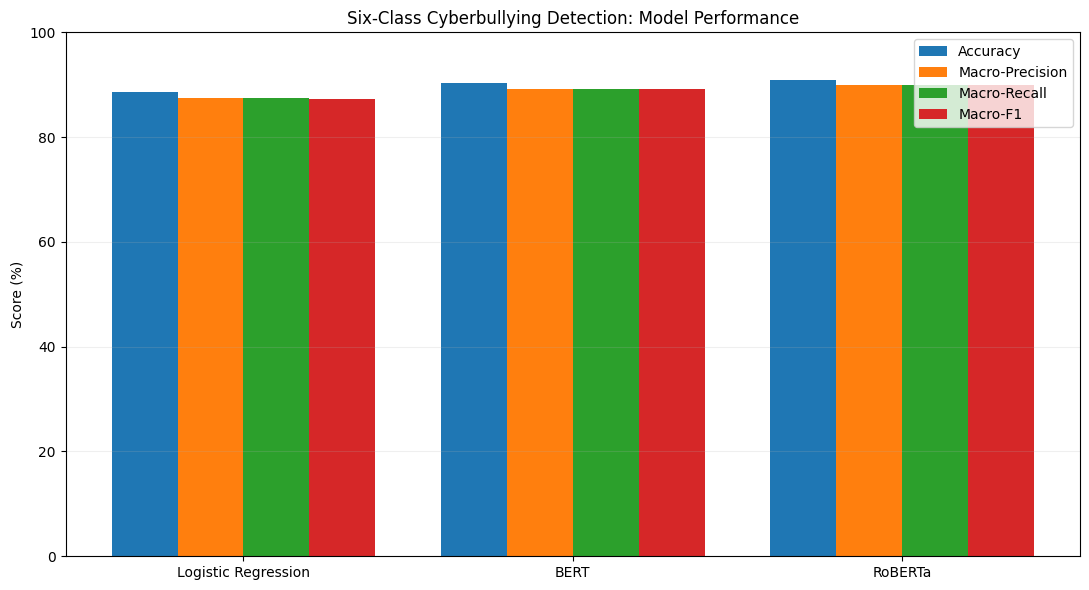

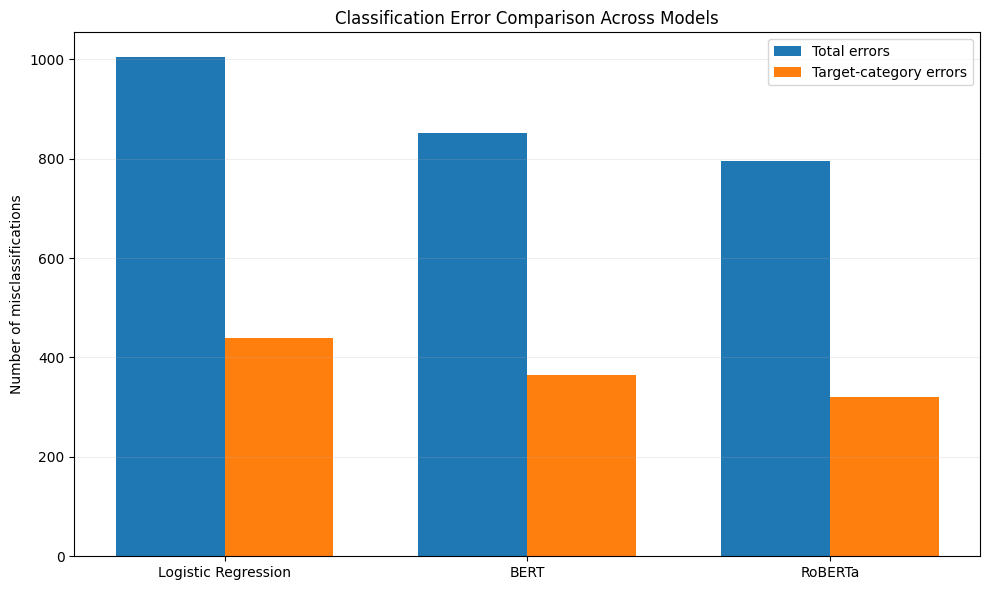

Figures saved to: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/figures
Saved figure files: ['model_error_comparison.png', 'model_error_comparison.svg', 'model_performance_comparison.png', 'model_performance_comparison.svg']


In [ ]:

import matplotlib.pyplot as plt  # Create evaluation figures
import numpy as np  # Calculate chart positions

figures_dir = results_dir / "figures"  # Define figure storage folder
figures_dir.mkdir(parents=True, exist_ok=True)  # Create figure folder if needed

plot_data = model_comparison.set_index("model").loc[["Logistic Regression", "BERT", "RoBERTa"]]  # Arrange models consistently
metrics = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]  # Select performance metrics
metric_labels = ["Accuracy", "Macro-Precision", "Macro-Recall", "Macro-F1"]  # Define chart labels

x = np.arange(len(plot_data))  # Calculate model positions
width = 0.2  # Define bar width

fig, ax = plt.subplots(figsize=(11, 6))  # Create performance chart

for i, metric in enumerate(metrics):  # Plot each evaluation metric
    ax.bar(x + (i - 1.5) * width, plot_data[metric] * 100, width, label=metric_labels[i])  # Draw metric bars

ax.set_xticks(x)  # Set model tick positions
ax.set_xticklabels(plot_data.index)  # Display model names
ax.set_ylabel("Score (%)")  # Label vertical axis
ax.set_ylim(0, 100)  # Use full percentage scale
ax.set_title("Six-Class Cyberbullying Detection: Model Performance")  # Add chart title
ax.legend()  # Display metric legend
ax.grid(axis="y", alpha=0.2)  # Add subtle gridlines
fig.tight_layout()  # Adjust figure spacing

fig.savefig(figures_dir / "model_performance_comparison.png", dpi=300, bbox_inches="tight")  # Save high-resolution PNG
fig.savefig(figures_dir / "model_performance_comparison.svg", bbox_inches="tight")  # Save scalable SVG
plt.show()  # Display performance chart

error_plot = error_comparison.set_index("model").loc[["Logistic Regression", "BERT", "RoBERTa"]]  # Arrange error data
fig, ax = plt.subplots(figsize=(10, 6))  # Create error comparison chart

ax.bar(x - 0.18, error_plot["total_errors"], 0.36, label="Total errors")  # Plot total classification errors
ax.bar(x + 0.18, error_plot["target_pair_errors"], 0.36, label="Target-category errors")  # Plot target-category errors

ax.set_xticks(x)  # Set model tick positions
ax.set_xticklabels(error_plot.index)  # Display model names
ax.set_ylabel("Number of misclassifications")  # Label vertical axis
ax.set_title("Classification Error Comparison Across Models")  # Add chart title
ax.legend()  # Display error legend
ax.grid(axis="y", alpha=0.2)  # Add subtle gridlines
fig.tight_layout()  # Adjust figure spacing

fig.savefig(figures_dir / "model_error_comparison.png", dpi=300, bbox_inches="tight")  # Save high-resolution PNG
fig.savefig(figures_dir / "model_error_comparison.svg", bbox_inches="tight")  # Save scalable SVG
plt.show()  # Display error chart

print("Figures saved to:", figures_dir)  # Confirm output location
print("Saved figure files:", sorted(file.name for file in figures_dir.glob("model_*")))  # List saved figures



### 6.3 Comparative Confusion Matrix Visualisation

The confusion matrices of Logistic Regression, BERT, and RoBERTa are compared to examine classification performance across the six cyberbullying categories.

The visualisation highlights correct predictions along the main diagonal and misclassifications outside the diagonal.

Particular attention is given to confusion between not_cyberbullying and other_cyberbullying, which represents a major classification challenge.

The comparison provides a visual assessment of whether contextual transformer models reduce category confusion relative to the classical NLP baseline.

The resulting figure is saved in PNG and SVG formats for inclusion in the final report.


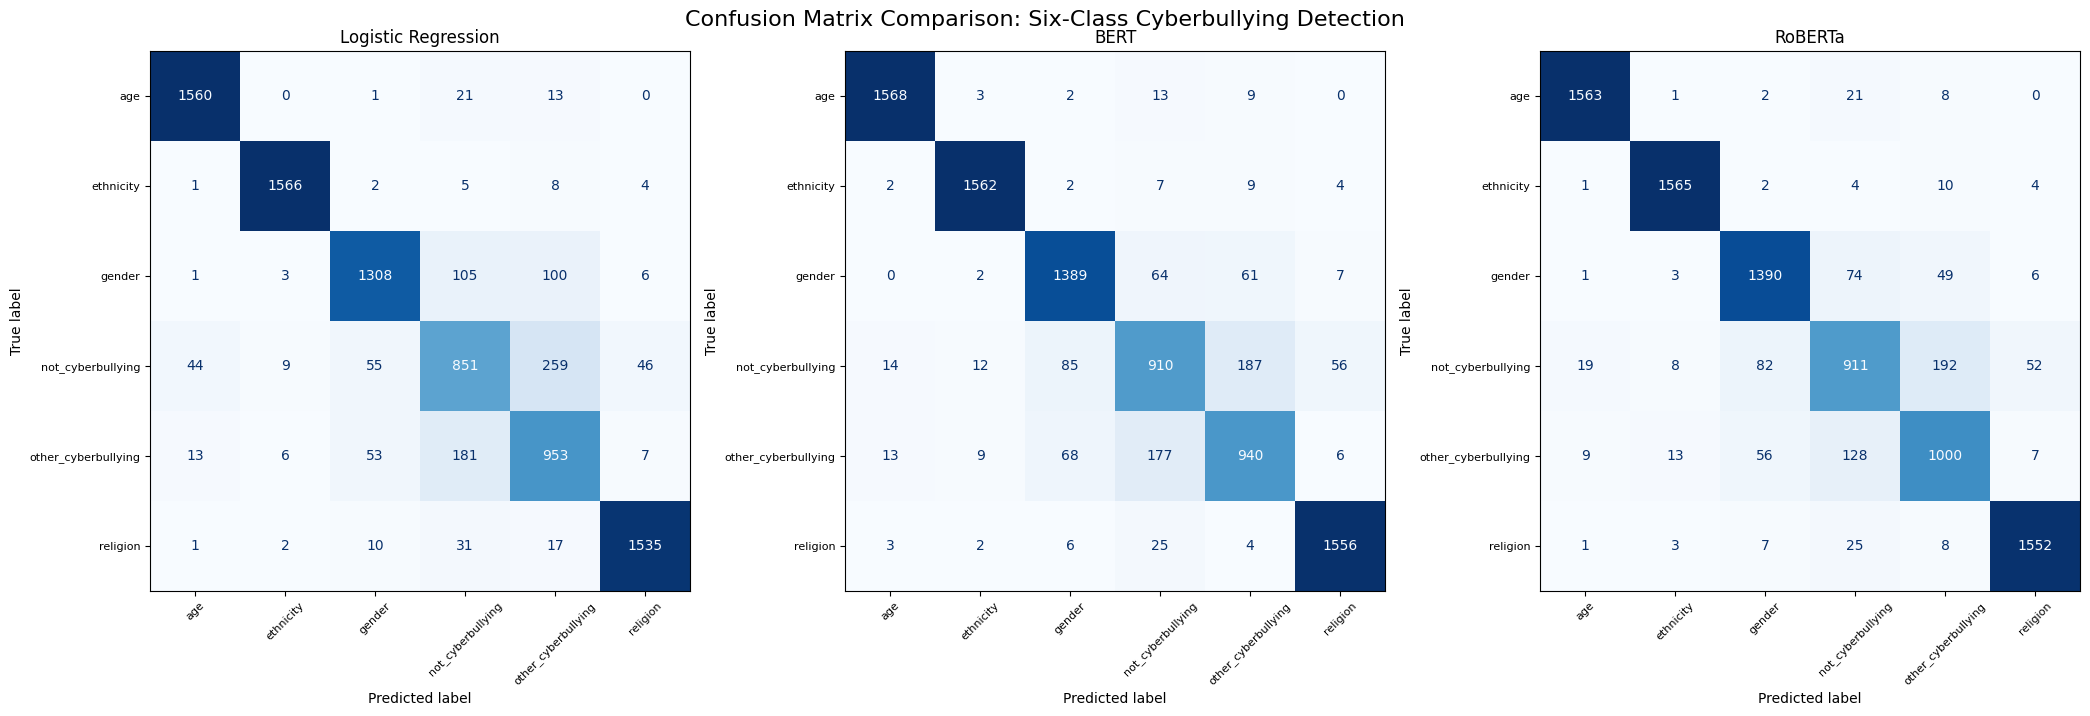

Saved: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/figures/confusion_matrix_comparison.png
Saved: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/figures/confusion_matrix_comparison.svg


In [ ]:

import matplotlib.pyplot as plt  # Create confusion matrix visualisations
import numpy as np  # Manage confusion matrix values
from sklearn.metrics import confusion_matrix  # Calculate classification confusion matrices
from sklearn.metrics import ConfusionMatrixDisplay  # Display confusion matrices

baseline_cm = np.array([[1560, 0, 1, 21, 13, 0], [1, 1566, 2, 5, 8, 4], [1, 3, 1308, 105, 100, 6], [44, 9, 55, 851, 259, 46], [13, 6, 53, 181, 953, 7], [1, 2, 10, 31, 17, 1535]])  # Reuse verified baseline confusion matrix

matrices = [baseline_cm, bert_cm, roberta_cm]  # Collect three confusion matrices
model_names = ["Logistic Regression", "BERT", "RoBERTa"]  # Define model titles

fig, axes = plt.subplots(1, 3, figsize=(21, 7))  # Create three side-by-side panels

for ax, matrix, model_name in zip(axes, matrices, model_names):  # Plot each model's confusion matrix
    display_cm = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=class_names)  # Configure matrix display
    display_cm.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d", xticks_rotation=45)  # Draw confusion matrix
    ax.set_title(model_name)  # Add model title
    ax.tick_params(axis="both", labelsize=8)  # Improve label readability

fig.suptitle("Confusion Matrix Comparison: Six-Class Cyberbullying Detection", fontsize=16)  # Add overall title
fig.tight_layout()  # Adjust spacing

fig.savefig(figures_dir / "confusion_matrix_comparison.png", dpi=300, bbox_inches="tight")  # Save high-resolution figure
fig.savefig(figures_dir / "confusion_matrix_comparison.svg", bbox_inches="tight")  # Save scalable figure

plt.show()  # Display confusion matrix comparison

print("Saved:", figures_dir / "confusion_matrix_comparison.png")  # Confirm PNG location
print("Saved:", figures_dir / "confusion_matrix_comparison.svg")  # Confirm SVG location



## 7. Annotation Robustness Analysis

### 7.1 Identifying Conflicting Annotations

Annotation robustness is investigated by examining conflicting class labels in the original cyberbullying dataset.

A conflicting annotation occurs when identical tweet text is associated with more than one cyberbullying category.

These cases may indicate annotation ambiguity or inconsistent labelling, although disagreement alone does not establish which label is correct.

The analysis identifies conflicting texts, measures their frequency, and examines the label combinations involved.

This descriptive audit provides the foundation for subsequent annotation robustness experiments without modifying the existing held-out test dataset.


In [ ]:

import pandas as pd  # Analyse original dataset annotations

original_path = dataset_dir / "cleaned_cyberbullying.csv"  # Locate available cleaned dataset
cleaned_df = pd.read_csv(original_path)  # Load cleaned dataset for inspection

print("Dataset columns:", cleaned_df.columns.tolist())  # Display available columns
print("Dataset records:", len(cleaned_df))  # Display dataset size
print("Missing values:", cleaned_df.isna().sum().to_dict())  # Check missing values

if {"text", "label"}.issubset(cleaned_df.columns):  # Check standardised column names
    text_column, label_column = "text", "label"  # Select standardised columns
elif {"tweet_text", "cyberbullying_type"}.issubset(cleaned_df.columns):  # Check original column names
    text_column, label_column = "tweet_text", "cyberbullying_type"  # Select original columns
else:  # Handle unexpected dataset structure
    raise ValueError("Expected text and label columns were not found.")  # Stop for column verification

conflict_counts = cleaned_df.groupby(text_column)[label_column].nunique()  # Count distinct labels per text
conflicting_texts = conflict_counts[conflict_counts > 1].index  # Identify texts with conflicting labels
conflicting_records = cleaned_df[cleaned_df[text_column].isin(conflicting_texts)].copy()  # Extract conflicting records

conflicting_records.to_csv(results_dir / "comparisons" / "cleaned_annotation_conflicts.csv", index=False)  # Save conflict records

print("Unique conflicting texts:", len(conflicting_texts))  # Display conflicting text count
print("Records involved in conflicts:", len(conflicting_records))  # Display affected records
print("Saved conflict audit:", results_dir / "comparisons" / "cleaned_annotation_conflicts.csv")  # Confirm saved output


Dataset columns: ['tweet_text', 'cyberbullying_type', 'clean_text']
Dataset records: 43884
Missing values: {'tweet_text': 0, 'cyberbullying_type': 0, 'clean_text': 0}
Unique conflicting texts: 0
Records involved in conflicts: 0
Saved conflict audit: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/comparisons/cleaned_annotation_conflicts.csv



### 7.2 Original Dataset Annotation Conflict Audit

The original cyberbullying dataset is examined to identify texts associated with multiple class labels before preprocessing.

Conflicting annotations are analysed to assess potential ambiguity and inconsistency across the six cyberbullying categories.

The number of conflicting texts, affected records, and label combinations are calculated.

These findings provide evidence for the annotation robustness component of the project.

The original dataset is analysed separately to preserve the existing training, validation, and held-out testing partitions.


In [ ]:

import pandas as pd  # Analyse original annotations

original_file = dataset_dir / "cyberbullying_tweets.csv"  # Locate original dataset

if not original_file.is_file():  # Check original dataset availability
    raise FileNotFoundError("Upload cyberbullying_tweets.csv to the Google Drive datasets folder first.")  # Stop if file is missing

original_df = pd.read_csv(original_file)  # Load unfiltered source dataset

required_columns = {"tweet_text", "cyberbullying_type"}  # Define required source columns
assert required_columns.issubset(original_df.columns), "Unexpected source dataset columns."  # Verify source structure

original_conflict_counts = original_df.groupby("tweet_text")["cyberbullying_type"].nunique()  # Count distinct labels per exact text
original_conflicting_texts = original_conflict_counts[original_conflict_counts > 1].index  # Identify conflicting texts
original_conflicts = original_df[original_df["tweet_text"].isin(original_conflicting_texts)].copy()  # Extract conflicting records

original_conflicts.to_csv(comparison_dir / "original_annotation_conflicts.csv", index=False)  # Save conflict records

conflict_label_groups = original_conflicts.groupby("tweet_text")["cyberbullying_type"].apply(lambda labels: " | ".join(sorted(labels.unique())))  # Summarise labels for each text
conflict_patterns = conflict_label_groups.value_counts().rename_axis("label_combination").reset_index(name="text_count")  # Count conflict patterns
conflict_patterns.to_csv(comparison_dir / "annotation_conflict_patterns.csv", index=False)  # Save conflict patterns

print("Original dataset records:", len(original_df))  # Display source size
print("Unique conflicting texts:", len(original_conflicting_texts))  # Display conflict count
print("Records involved in conflicts:", len(original_conflicts))  # Display affected records
print("Conflict percentage of unique texts:", round(100 * len(original_conflicting_texts) / original_df["tweet_text"].nunique(), 2))  # Calculate conflict rate
display(conflict_patterns.head(10))  # Display most common conflicting label combinations


Original dataset records: 47692
Unique conflicting texts: 1640
Records involved in conflicts: 3290
Conflict percentage of unique texts: 3.56


,label_combination,text_count
0,not_cyberbullying | other_cyberbullying,1456
1,gender | other_cyberbullying,124
2,gender | not_cyberbullying,50
3,ethnicity | religion,4
4,ethnicity | not_cyberbullying,2
5,age | ethnicity | gender | other_cyberbullying...,1
6,ethnicity | gender,1
7,gender | religion,1
8,not_cyberbullying | religion,1



### 7.3 Annotation Conflict Distribution

The distribution of conflicting annotations is examined to identify the category combinations most frequently associated with disagreement.

Particular attention is given to not_cyberbullying and other_cyberbullying, which account for the majority of conflicting texts in the original dataset.

Conflict frequencies and percentages are calculated and visualised to assess the concentration of annotation ambiguity.

The analysis is descriptive and does not assume that conflicting labels are necessarily incorrect.

The resulting statistics and visualisations are saved to Google Drive for use in the final report and subsequent annotation robustness experiments.


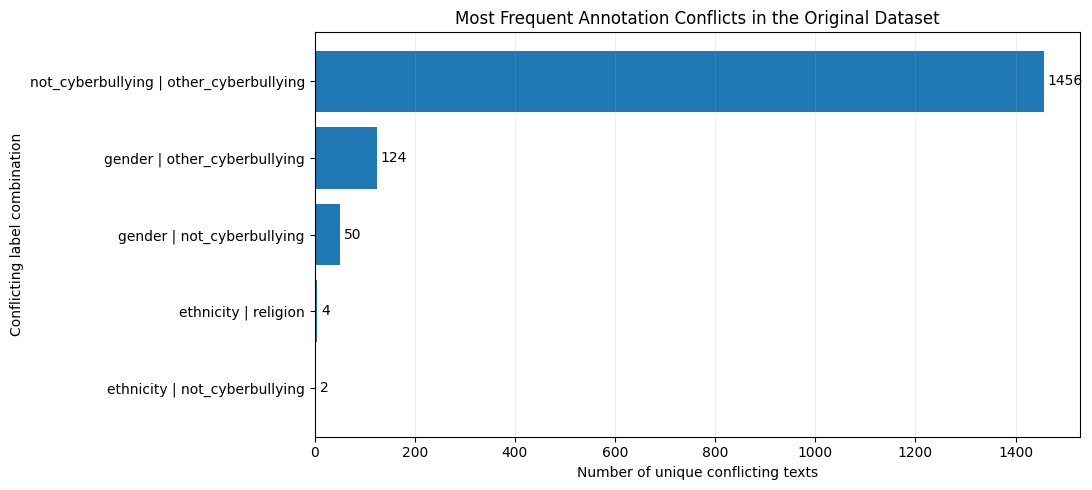

Total conflicting texts: 1640
Target-category conflict percentage: 88.78 %


,label_combination,text_count,percentage
0,not_cyberbullying | other_cyberbullying,1456,88.780488
1,gender | other_cyberbullying,124,7.560976
2,gender | not_cyberbullying,50,3.048780
3,ethnicity | religion,4,0.243902
4,ethnicity | not_cyberbullying,2,0.121951
5,age | ethnicity | gender | other_cyberbullying...,1,0.060976
6,ethnicity | gender,1,0.060976
7,gender | religion,1,0.060976
8,not_cyberbullying | religion,1,0.060976


Saved figures to: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/figures


In [ ]:

import pandas as pd  # Organise annotation conflict statistics
import matplotlib.pyplot as plt  # Create conflict distribution figure

conflict_distribution = conflict_patterns.copy()  # Reuse verified conflict patterns
conflict_distribution["percentage"] = 100 * conflict_distribution["text_count"] / len(original_conflicting_texts)  # Calculate conflict percentages
conflict_distribution.to_csv(comparison_dir / "annotation_conflict_distribution.csv", index=False)  # Save distribution results

top_conflicts = conflict_distribution.head(5).copy()  # Select five most frequent conflict patterns

fig, ax = plt.subplots(figsize=(11, 5))  # Create distribution figure
bars = ax.barh(top_conflicts["label_combination"], top_conflicts["text_count"])  # Plot conflict frequencies
ax.invert_yaxis()  # Display most frequent pattern first
ax.set_xlabel("Number of unique conflicting texts")  # Label horizontal axis
ax.set_ylabel("Conflicting label combination")  # Label vertical axis
ax.set_title("Most Frequent Annotation Conflicts in the Original Dataset")  # Add figure title
ax.bar_label(bars, padding=3)  # Display frequencies on bars
ax.grid(axis="x", alpha=0.2)  # Add subtle gridlines
fig.tight_layout()  # Improve figure spacing

fig.savefig(figures_dir / "annotation_conflict_distribution.png", dpi=300, bbox_inches="tight")  # Save PNG figure
fig.savefig(figures_dir / "annotation_conflict_distribution.svg", bbox_inches="tight")  # Save SVG figure
plt.show()  # Display conflict distribution

print("Total conflicting texts:", len(original_conflicting_texts))  # Display conflict count
print("Target-category conflict percentage:", round(100 * 1456 / len(original_conflicting_texts), 2), "%")  # Display target conflict share
display(conflict_distribution.head(10))  # Display conflict statistics
print("Saved figures to:", figures_dir)  # Confirm figure storage



### 7.4 Annotation Robustness Experiment Preparation

A separate annotation-disagreement evaluation dataset is constructed from the original cyberbullying records containing conflicting labels.

Each unique conflicting text is retained once, together with its associated set of original class annotations.

The dataset is used to investigate how BERT and RoBERTa respond to texts with disputed labels.

Because these annotations do not establish a single reliable ground-truth category, the experiment focuses on prediction agreement, annotation compatibility, and model disagreement rather than conventional classification accuracy.

The original training, validation, and held-out testing partitions remain unchanged.

Potential overlap with previously used model-development texts is checked and reported before interpreting the findings.


In [ ]:

import json  # Store competing annotations
import pandas as pd  # Organise disagreement records

conflict_dataset = original_conflicts.groupby("tweet_text")["cyberbullying_type"].apply(lambda labels: sorted(labels.unique().tolist())).reset_index(name="annotation_labels")  # Keep one row per conflicting text
conflict_dataset = conflict_dataset.rename(columns={"tweet_text": "text"})  # Standardise text column name
conflict_dataset["annotation_count"] = conflict_dataset["annotation_labels"].apply(len)  # Count distinct annotations
conflict_dataset["annotation_labels"] = conflict_dataset["annotation_labels"].apply(json.dumps)  # Store annotation lists as JSON strings

train_texts = set(train_df["text"].astype(str))  # Collect training texts
val_texts = set(val_df["text"].astype(str))  # Collect validation texts
test_texts = set(test_df["text"].astype(str))  # Collect held-out testing texts

conflict_dataset["in_training"] = conflict_dataset["text"].isin(train_texts)  # Check training overlap
conflict_dataset["in_validation"] = conflict_dataset["text"].isin(val_texts)  # Check validation overlap
conflict_dataset["in_testing"] = conflict_dataset["text"].isin(test_texts)  # Check test overlap

conflict_dataset.to_csv(comparison_dir / "annotation_disagreement_dataset.csv", index=False)  # Save disagreement dataset

print("Unique disagreement texts:", len(conflict_dataset))  # Display dataset size
print("Overlap with training:", int(conflict_dataset["in_training"].sum()))  # Display training overlap
print("Overlap with validation:", int(conflict_dataset["in_validation"].sum()))  # Display validation overlap
print("Overlap with testing:", int(conflict_dataset["in_testing"].sum()))  # Display test overlap
print("Texts with more than two competing labels:", int((conflict_dataset["annotation_count"] > 2).sum()))  # Count multi-label disagreements
print("Saved dataset:", comparison_dir / "annotation_disagreement_dataset.csv")  # Confirm storage location
display(conflict_dataset.drop(columns=["text"]).head(10))  # Preview annotations without displaying tweet contents


Unique disagreement texts: 1640
Overlap with training: 0
Overlap with validation: 0
Overlap with testing: 0
Texts with more than two competing labels: 1
Saved dataset: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/comparisons/annotation_disagreement_dataset.csv


,annotation_labels,annotation_count,in_training,in_validation,in_testing
0,"[""gender"", ""other_cyberbullying""]",2,False,False,False
1,"[""gender"", ""not_cyberbullying""]",2,False,False,False
2,"[""gender"", ""not_cyberbullying""]",2,False,False,False
3,"[""gender"", ""other_cyberbullying""]",2,False,False,False
4,"[""not_cyberbullying"", ""other_cyberbullying""]",2,False,False,False
5,"[""age"", ""ethnicity"", ""gender"", ""other_cyberbul...",5,False,False,False
6,"[""not_cyberbullying"", ""other_cyberbullying""]",2,False,False,False
7,"[""gender"", ""other_cyberbullying""]",2,False,False,False
8,"[""not_cyberbullying"", ""other_cyberbullying""]",2,False,False,False
9,"[""not_cyberbullying"", ""other_cyberbullying""]",2,False,False,False



### 7.5 Normalised Text Overlap Verification

The annotation-disagreement dataset is checked against the training, validation, and held-out test datasets using the text normalisation rules applied during preprocessing.

URLs and user mentions are replaced with standard placeholders, and repeated whitespace is collapsed.

This verification identifies potential overlaps that may not be detected through exact string matching.

Any overlapping records are excluded from the independent disagreement evaluation subset, while the complete disagreement dataset is retained for descriptive analysis.

The existing model-development datasets and trained models remain unchanged.


In [ ]:

import re  # Apply text normalisation
import pandas as pd  # Manage disagreement records

def normalise_overlap_text(text):  # Define overlap-check normalisation
    text = str(text)  # Convert input to text
    text = re.sub(r"https?://\S+|www\.\S+", "URL", text)  # Replace web addresses
    text = re.sub(r"@\w+", "USER", text)  # Replace user mentions
    text = re.sub(r"\s+", " ", text).strip()  # Collapse whitespace
    return text  # Return normalised text

development_texts = pd.concat([train_df["text"], val_df["text"], test_df["text"]], ignore_index=True)  # Combine development texts
development_keys = set(development_texts.map(normalise_overlap_text))  # Build normalised lookup set

conflict_dataset["normalised_text"] = conflict_dataset["text"].map(normalise_overlap_text)  # Normalise disagreement texts
conflict_dataset["normalised_overlap"] = conflict_dataset["normalised_text"].isin(development_keys)  # Detect normalised overlaps

independent_conflicts = conflict_dataset.loc[~conflict_dataset["normalised_overlap"]].copy()  # Retain non-overlapping records
independent_conflicts.to_csv(comparison_dir / "independent_annotation_disagreements.csv", index=False)  # Save evaluation subset

print("Original conflicting texts:", len(conflict_dataset))  # Display original disagreement count
print("Normalised overlaps:", int(conflict_dataset["normalised_overlap"].sum()))  # Display overlap count
print("Non-overlapping disagreement texts:", len(independent_conflicts))  # Display retained records
print("Saved:", comparison_dir / "independent_annotation_disagreements.csv")  # Confirm output file


Original conflicting texts: 1640
Normalised overlaps: 11
Non-overlapping disagreement texts: 1629
Saved: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/comparisons/independent_annotation_disagreements.csv



### 7.6 BERT and RoBERTa Prediction Agreement on Disputed Annotations

The fine-tuned BERT and RoBERTa models are evaluated on a separate subset of original texts containing conflicting annotations.

The subset excludes texts that overlap with the training, validation, or held-out testing partitions after normalisation.

Each transformer predicts one of the six cyberbullying categories for every disagreement text.

The analysis measures agreement between the models and whether their predictions are compatible with at least one of the original annotations.

Because the annotations are disputed, prediction compatibility is not interpreted as classification accuracy.

The results are saved for subsequent robustness analysis and comparison.


In [ ]:

import json  # Decode competing annotation sets
import numpy as np  # Process prediction scores
import pandas as pd  # Organise robustness results
from datasets import Dataset  # Prepare Hugging Face datasets

robustness_df = independent_conflicts.copy().reset_index(drop=True)  # Prepare independent disagreement records
robustness_df["annotation_labels"] = robustness_df["annotation_labels"].apply(json.loads)  # Decode original label sets

robustness_dataset = Dataset.from_pandas(robustness_df[["text"]], preserve_index=False)  # Create prediction dataset

bert_robustness_dataset = robustness_dataset.map(lambda batch: bert_tokenizer(batch["text"], truncation=True, max_length=128), batched=True, remove_columns=["text"])  # Tokenise texts for BERT
roberta_robustness_dataset = robustness_dataset.map(lambda batch: roberta_tokenizer(batch["text"], truncation=True, max_length=128), batched=True, remove_columns=["text"])  # Tokenise texts for RoBERTa

bert_robustness_output = bert_trainer.predict(bert_robustness_dataset)  # Generate BERT predictions
roberta_robustness_output = roberta_trainer.predict(roberta_robustness_dataset)  # Generate RoBERTa predictions

bert_robustness_ids = np.argmax(bert_robustness_output.predictions, axis=1)  # Select BERT predicted classes
roberta_robustness_ids = np.argmax(roberta_robustness_output.predictions, axis=1)  # Select RoBERTa predicted classes

robustness_df["bert_prediction"] = [class_names[i] for i in bert_robustness_ids]  # Decode BERT predictions
robustness_df["roberta_prediction"] = [class_names[i] for i in roberta_robustness_ids]  # Decode RoBERTa predictions

robustness_df["models_agree"] = robustness_df["bert_prediction"] == robustness_df["roberta_prediction"]  # Identify agreement between models
robustness_df["bert_annotation_compatible"] = robustness_df.apply(lambda row: row["bert_prediction"] in row["annotation_labels"], axis=1)  # Check BERT annotation compatibility
robustness_df["roberta_annotation_compatible"] = robustness_df.apply(lambda row: row["roberta_prediction"] in row["annotation_labels"], axis=1)  # Check RoBERTa annotation compatibility

robustness_df["annotation_labels"] = robustness_df["annotation_labels"].apply(json.dumps)  # Convert annotation sets for CSV storage
robustness_df.to_csv(comparison_dir / "transformer_annotation_robustness_predictions.csv", index=False)  # Save detailed predictions

robustness_summary = pd.DataFrame([{"evaluation_records": len(robustness_df), "model_agreement_percentage": 100 * robustness_df["models_agree"].mean(), "bert_annotation_compatibility_percentage": 100 * robustness_df["bert_annotation_compatible"].mean(), "roberta_annotation_compatibility_percentage": 100 * robustness_df["roberta_annotation_compatible"].mean()}])  # Summarise robustness measurements
robustness_summary.to_csv(comparison_dir / "transformer_annotation_robustness_summary.csv", index=False)  # Save summary statistics

print("Disagreement texts evaluated:", len(robustness_df))  # Display evaluation size
print("BERT–RoBERTa agreement:", round(robustness_summary["model_agreement_percentage"].iloc[0], 2), "%")  # Display model agreement
print("BERT annotation compatibility:", round(robustness_summary["bert_annotation_compatibility_percentage"].iloc[0], 2), "%")  # Display BERT compatibility
print("RoBERTa annotation compatibility:", round(robustness_summary["roberta_annotation_compatibility_percentage"].iloc[0], 2), "%")  # Display RoBERTa compatibility
print("Saved results to:", comparison_dir)  # Confirm output directory


Map:   0%|          | 0/1629 [00:00<?, ? examples/s]

Map:   0%|          | 0/1629 [00:00<?, ? examples/s]

Disagreement texts evaluated: 1629
BERT–RoBERTa agreement: 80.6 %
BERT annotation compatibility: 91.59 %
RoBERTa annotation compatibility: 91.65 %
Saved results to: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/comparisons



### 7.7 Annotation Robustness Interpretation and Visualisation

The annotation robustness results are summarised by comparing BERT and RoBERTa predictions on 1,629 non-overlapping texts with conflicting original annotations.

Prediction agreement and annotation compatibility are used to characterise model behaviour under annotation disagreement.

The analysis also identifies the most frequent categories involved when BERT and RoBERTa make different predictions.

These measurements are interpreted as descriptive indicators rather than ground-truth classification accuracy or direct evidence of model robustness to annotation changes.

The resulting tables and figures are saved to Google Drive for inclusion in the final report.


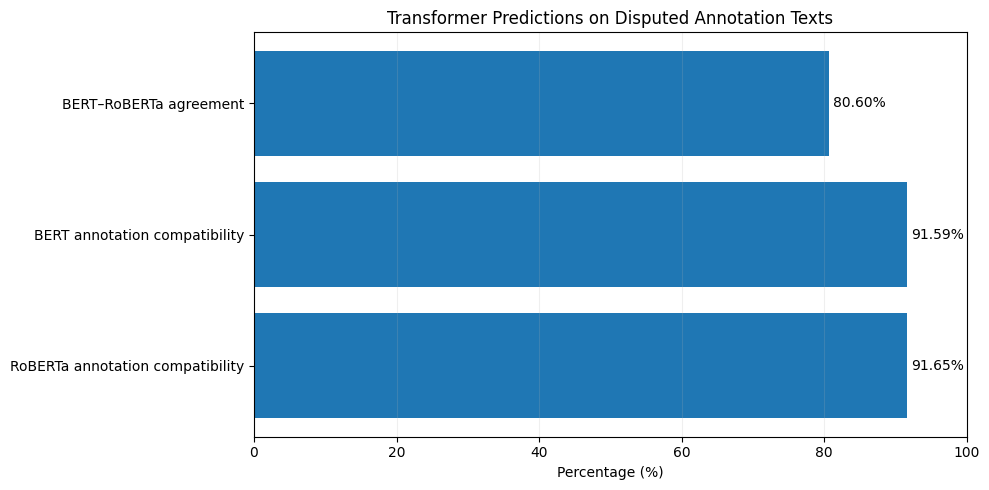

Total evaluated texts: 1629
Model disagreements: 316
Model agreement: 80.6 %


,bert_prediction,roberta_prediction,count
10,not_cyberbullying,other_cyberbullying,148
14,other_cyberbullying,not_cyberbullying,91
13,other_cyberbullying,gender,18
5,gender,other_cyberbullying,11
9,not_cyberbullying,gender,10
4,gender,not_cyberbullying,10
2,ethnicity,other_cyberbullying,8
12,other_cyberbullying,ethnicity,7
8,not_cyberbullying,ethnicity,4
0,age,not_cyberbullying,2


Saved results to: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/results/comparisons


In [ ]:

import matplotlib.pyplot as plt  # Create robustness visualisations
import pandas as pd  # Organise model disagreement statistics

robustness_plot = pd.DataFrame({"Measurement": ["BERT–RoBERTa agreement", "BERT annotation compatibility", "RoBERTa annotation compatibility"], "Percentage": [100 * robustness_df["models_agree"].mean(), 100 * robustness_df["bert_annotation_compatible"].mean(), 100 * robustness_df["roberta_annotation_compatible"].mean()]})  # Prepare summary data

fig, ax = plt.subplots(figsize=(10, 5))  # Create summary chart
bars = ax.barh(robustness_plot["Measurement"], robustness_plot["Percentage"])  # Plot robustness measurements
ax.invert_yaxis()  # Display agreement first
ax.set_xlim(0, 100)  # Use percentage scale
ax.set_xlabel("Percentage (%)")  # Label horizontal axis
ax.set_title("Transformer Predictions on Disputed Annotation Texts")  # Add chart title
ax.bar_label(bars, fmt="%.2f%%", padding=3)  # Display percentage values
ax.grid(axis="x", alpha=0.2)  # Add subtle gridlines
fig.tight_layout()  # Improve figure layout

fig.savefig(figures_dir / "annotation_robustness_summary.png", dpi=300, bbox_inches="tight")  # Save PNG figure
fig.savefig(figures_dir / "annotation_robustness_summary.svg", bbox_inches="tight")  # Save SVG figure
plt.show()  # Display summary chart

model_disagreements = robustness_df.loc[~robustness_df["models_agree"]].copy()  # Select model disagreements
disagreement_pairs = model_disagreements.groupby(["bert_prediction", "roberta_prediction"]).size().reset_index(name="count")  # Count prediction differences
disagreement_pairs = disagreement_pairs.sort_values("count", ascending=False)  # Rank disagreement patterns

model_disagreements.to_csv(comparison_dir / "bert_roberta_disagreement_records.csv", index=False)  # Save disagreement records
disagreement_pairs.to_csv(comparison_dir / "bert_roberta_disagreement_pairs.csv", index=False)  # Save disagreement patterns

print("Total evaluated texts:", len(robustness_df))  # Display evaluation size
print("Model disagreements:", len(model_disagreements))  # Display disagreement count
print("Model agreement:", round(100 * robustness_df["models_agree"].mean(), 2), "%")  # Display agreement percentage
display(disagreement_pairs.head(10))  # Show most frequent disagreement patterns
print("Saved results to:", comparison_dir)  # Confirm output folder



## 8. Final Project Validation and Submission Preparation

### 8.1 Project Results Verification

The final project outputs are checked to confirm that the trained BERT and RoBERTa models, evaluation metrics, classification reports, prediction files, comparison tables, and annotation-disagreement results have been saved.

The verification also checks that the original datasets and held-out testing partitions remain available.

This process supports reproducibility and ensures that the required experimental evidence is retained before preparing the final report and submission package.


In [ ]:

from pathlib import Path  # Verify saved project files
import pandas as pd  # Inspect saved evaluation tables

required_files = {  # Define important project deliverables
    "Training dataset": results_dir / "datasets" / "transformer_train.csv",
    "Validation dataset": results_dir / "datasets" / "transformer_validation.csv",
    "Held-out test dataset": results_dir / "datasets" / "test_data.csv",
    "Original dataset": results_dir / "datasets" / "cyberbullying_tweets.csv",
    "BERT model": results_dir / "bert" / "best_model" / "config.json",
    "BERT metrics": results_dir / "bert" / "bert_test_metrics.csv",
    "BERT predictions": results_dir / "bert" / "bert_predictions.csv",
    "RoBERTa model": results_dir / "roberta" / "best_model" / "config.json",
    "RoBERTa metrics": results_dir / "roberta" / "roberta_test_metrics.csv",
    "RoBERTa predictions": results_dir / "roberta" / "roberta_predictions.csv",
    "Model comparison": results_dir / "comparisons" / "model_performance_comparison.csv",
    "Error comparison": results_dir / "comparisons" / "model_error_comparison.csv",
    "Annotation conflicts": results_dir / "comparisons" / "original_annotation_conflicts.csv",
    "Independent disagreement dataset": results_dir / "comparisons" / "independent_annotation_disagreements.csv",
    "Robustness predictions": results_dir / "comparisons" / "transformer_annotation_robustness_predictions.csv",
    "Robustness summary": results_dir / "comparisons" / "transformer_annotation_robustness_summary.csv",
    "Performance chart": results_dir / "figures" / "model_performance_comparison.png",
    "Error chart": results_dir / "figures" / "model_error_comparison.png",
    "Confusion matrices": results_dir / "figures" / "confusion_matrix_comparison.png",
    "Annotation conflict chart": results_dir / "figures" / "annotation_conflict_distribution.png",
    "Robustness chart": results_dir / "figures" / "annotation_robustness_summary.png",
}  # Finish required file list

verification = pd.DataFrame([{"deliverable": name, "exists": path.is_file(), "path": str(path)} for name, path in required_files.items()])  # Check each file
verification.to_csv(results_dir / "comparisons" / "project_file_verification.csv", index=False)  # Save verification report

print("Files checked:", len(verification))  # Display verification count
print("Files found:", int(verification["exists"].sum()))  # Display available files
print("Missing files:", int((~verification["exists"]).sum()))  # Display missing file count
display(verification[["deliverable", "exists"]])  # Show verification results


Files checked: 21
Files found: 21
Missing files: 0


,deliverable,exists
0,Training dataset,True
1,Validation dataset,True
2,Held-out test dataset,True
3,Original dataset,True
4,BERT model,True
5,BERT metrics,True
6,BERT predictions,True
7,RoBERTa model,True
8,RoBERTa metrics,True
9,RoBERTa predictions,True



### 8.2 Trained Model Integrity Verification

The saved BERT and RoBERTa model directories are inspected to verify that the model weights, configuration files, and tokenizer files are present.

The verification records the model weight filenames and sizes and confirms that each model can be loaded independently from its saved directory.

This supports reproducibility and reduces the risk of losing trained models when the Google Colab runtime disconnects.

The original training results and model checkpoints remain unchanged.


In [ ]:

from pathlib import Path  # Manage saved model directories
import pandas as pd  # Organise verification results
from transformers import AutoConfig, AutoTokenizer  # Verify saved configurations and tokenizers

model_checks = []  # Store model verification results

for model_name in ["bert", "roberta"]:  # Check both trained transformers
    model_dir = results_dir / model_name / "best_model"  # Locate saved model
    weight_files = list(model_dir.glob("*.safetensors")) + list(model_dir.glob("pytorch_model*.bin"))  # Find saved weights
    config_exists = (model_dir / "config.json").is_file()  # Check configuration file
    tokenizer_exists = (model_dir / "tokenizer.json").is_file()  # Check tokenizer file
    weight_size_mb = sum(file.stat().st_size for file in weight_files) / (1024 ** 2)  # Calculate weight size

    config = AutoConfig.from_pretrained(str(model_dir))  # Load saved model configuration
    tokenizer = AutoTokenizer.from_pretrained(str(model_dir))  # Load saved tokenizer

    model_checks.append({"model": model_name.upper(), "weights_found": bool(weight_files), "config_found": config_exists, "tokenizer_found": tokenizer_exists, "number_of_classes": config.num_labels, "weight_size_mb": round(weight_size_mb, 2)})  # Record verification results

model_integrity = pd.DataFrame(model_checks)  # Create verification table
model_integrity.to_csv(comparison_dir / "model_integrity_verification.csv", index=False)  # Save verification results

display(model_integrity)  # Display model integrity checks
print("All model files verified:", bool(model_integrity["weights_found"].all() and model_integrity["config_found"].all() and model_integrity["tokenizer_found"].all() and (model_integrity["number_of_classes"] == 6).all()))  # Confirm overall verification


,model,weights_found,config_found,tokenizer_found,number_of_classes,weight_size_mb
0,BERT,True,True,True,6,417.68
1,ROBERTA,True,True,True,6,475.53


All model files verified: True



### 8.3 Model Reloading and Prediction Reproducibility

The saved BERT and RoBERTa models are reloaded independently from their Google Drive directories.

A fixed sample of 100 held-out test records is used to verify that the reloaded models reproduce the predictions generated during the original evaluation.

Predictions are compared with previously saved test prediction files.

The procedure confirms that the trained models can be restored without retraining and that their predictions remain consistent.

The reproducibility results are saved for final project documentation.


In [ ]:

import gc  # Release model memory after verification
import pandas as pd  # Organise reproducibility results
import torch  # Run model inference
from transformers import AutoModelForSequenceClassification, AutoTokenizer  # Reload saved transformers

sample_indices = list(range(100))  # Select a fixed test sample
sample_texts = test_df.iloc[sample_indices]["text"].astype(str).tolist()  # Extract sample texts
reproducibility_results = []  # Store verification results

for model_name in ["bert", "roberta"]:  # Verify both saved models
    model_dir = results_dir / model_name / "best_model"  # Locate saved model directory
    saved_predictions = pd.read_csv(results_dir / model_name / f"{model_name}_predictions.csv")  # Load original predictions
    assert len(saved_predictions) == len(test_df), "Saved prediction count differs from test data."  # Check row count
    assert saved_predictions["text"].astype(str).tolist() == test_df["text"].astype(str).tolist(), "Prediction rows are not aligned."  # Verify text order

    tokenizer = AutoTokenizer.from_pretrained(str(model_dir))  # Reload saved tokenizer
    model = AutoModelForSequenceClassification.from_pretrained(str(model_dir)).to("cpu")  # Reload trained model on CPU
    model.eval()  # Enable inference mode

    new_predictions = []  # Collect reloaded predictions

    with torch.inference_mode():  # Disable gradient calculations
        for start in range(0, len(sample_texts), 16):  # Process small batches
            batch = sample_texts[start:start + 16]  # Select current text batch
            inputs = tokenizer(batch, padding=True, truncation=True, max_length=128, return_tensors="pt")  # Tokenise sample texts
            logits = model(**inputs).logits  # Calculate classification scores
            predicted_ids = logits.argmax(dim=-1).tolist()  # Select predicted classes
            new_predictions.extend([model.config.id2label[i] for i in predicted_ids])  # Decode class labels

    original_predictions = saved_predictions.iloc[sample_indices]["predicted_label"].astype(str).tolist()  # Retrieve saved labels
    matches = sum(a == b for a, b in zip(new_predictions, original_predictions))  # Count matching predictions
    reproducibility_results.append({"model": model_name.upper(), "samples_checked": len(sample_indices), "matching_predictions": matches, "match_percentage": 100 * matches / len(sample_indices)})  # Record results

    del model, tokenizer  # Release model references
    gc.collect()  # Clean unused memory

reproducibility_df = pd.DataFrame(reproducibility_results)  # Create verification table
reproducibility_df.to_csv(comparison_dir / "model_reproducibility_verification.csv", index=False)  # Save results
display(reproducibility_df)  # Display verification summary


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,model,samples_checked,matching_predictions,match_percentage
0,BERT,100,100,100.0
1,ROBERTA,100,100,100.0



### 8.4 Final Project Backup Preparation

A compressed backup of the completed project results is created for local storage and submission preparation.

The backup includes the original and processed datasets, trained BERT and RoBERTa models, evaluation results, comparison tables, annotation-disagreement analysis, and generated figures.

The original files remain unchanged in Google Drive.

The Google Colab notebook and original VS Code notebook will be added to the final Desktop project folder separately to preserve the complete development workflow.


In [32]:

import shutil  # Create a compressed project backup
from pathlib import Path  # Manage backup paths

backup_dir = project_dir / "backups"  # Define persistent backup folder
backup_dir.mkdir(parents=True, exist_ok=True)  # Create backup folder

backup_base = backup_dir / "Cyberbullying_NLP_Final_2026_Results"  # Define backup filename
backup_path = shutil.make_archive(str(backup_base), "zip", root_dir=project_dir, base_dir="results")  # Compress results folder

backup_size_gb = Path(backup_path).stat().st_size / (1024 ** 3)  # Calculate backup size

print("Backup created:", backup_path)  # Display backup location
print("Backup size (GB):", round(backup_size_gb, 2))  # Display backup size
print("Backup exists:", Path(backup_path).is_file())  # Verify backup file


Backup created: /content/drive/MyDrive/Cyberbullying_NLP_Final_2026/backups/Cyberbullying_NLP_Final_2026_Results.zip
Backup size (GB): 5.2
Backup exists: True
